PA3 — Parte 0

In [ ]:
!git clone https://github.com/GeorgeRV/DL_PA3.git

Cloning into 'DL_PA3'...
remote: Enumerating objects: 52, done.
remote: Total 52 (delta 0), reused 0 (delta 0), pack-reused 52 (from 1)
Receiving objects: 100% (52/52), 120.87 MiB | 19.79 MiB/s, done.
Resolving deltas: 100% (4/4), done.


In [ ]:
%cd DL_PA3/
!pip install -r requirements.txt

/content/DL_PA3


In [ ]:
import subprocess
import zipfile
import shutil
from pathlib import Path

DATA_ZIP = Path('data/pa3_dados.zip')
DATA_EXTRACT_DIR = Path('data/')

with zipfile.ZipFile(DATA_ZIP) as zf:
    zf.extractall(DATA_EXTRACT_DIR)

# Localiza automaticamente a raiz do dataset, mesmo que o ZIP tenha
# uma pasta externa envolvendo images/, labels/ e classes.csv.
rotulo_files = list(DATA_EXTRACT_DIR.rglob('rotulos_5.csv'))
valid_roots = [p.parent.parent for p in rotulo_files
               if p.parent.name == 'labels'
               and (p.parent.parent / 'images').is_dir()
               and (p.parent.parent / 'classes.csv').is_file()]

if len(valid_roots) != 1:
    raise RuntimeError(
        'Não consegui identificar uma única pasta raiz do dataset. '
        f'Raízes candidatas encontradas: {valid_roots}'
    )

DATA_DIR = valid_roots[0]
print('Dataset localizado em:', DATA_DIR)
print('Conteúdo:', sorted(p.name for p in DATA_DIR.iterdir()))

Dataset localizado em: data/pa3_dados
Conteúdo: ['LEIAME.md', 'classes.csv', 'images', 'labels']


In [ ]:
!python -m src.train_piso --data-dir data/pa3_dados --output-dir outputs/parte0 --models both

Dispositivo: cuda
Seed: 42
Classes: 21
Treino rotulado: 105 imagens
Validação: 202 imagens
O test_public não será usado no treinamento nem na seleção de época.

[cnn_scratch] Parâmetros treináveis/totais: 342,453
[cnn_scratch] Época 001/60 | loss treino 3.0961 | loss val 3.0287 | F1 treino 0.0171 | F1 val 0.0376
[cnn_scratch] Época 002/60 | loss treino 2.9601 | loss val 3.0128 | F1 treino 0.0480 | F1 val 0.0425
[cnn_scratch] Época 003/60 | loss treino 2.8493 | loss val 2.9872 | F1 treino 0.1091 | F1 val 0.0931
[cnn_scratch] Época 004/60 | loss treino 2.7792 | loss val 2.9145 | F1 treino 0.0753 | F1 val 0.0696
[cnn_scratch] Época 005/60 | loss treino 2.7532 | loss val 2.8580 | F1 treino 0.0501 | F1 val 0.0335
[cnn_scratch] Época 006/60 | loss treino 2.6751 | loss val 2.8293 | F1 treino 0.1437 | F1 val 0.0597
[cnn_scratch] Época 007/60 | loss treino 2.6569 | loss val 2.8341 | F1 treino 0.1729 | F1 val 0.0808
[cnn_scratch] Época 008/60 | loss treino 2.5788 | loss val 2.7733 | F1 treino 0.

In [ ]:
!python -m src.evaluate --data-dir data/pa3_dados --output-dir outputs/parte0 --models both


=== cnn_scratch — test_public ===
F1 macro: 0.1739
Acurácia: 0.2306
Cross-entropy: 2.7766
Parâmetros: 342,453
Resultados: outputs/parte0/cnn_scratch

=== resnet18 — test_public ===
F1 macro: 0.3892
Acurácia: 0.4316
Cross-entropy: 1.9904
Parâmetros: 11,187,285
Resultados: outputs/parte0/resnet18


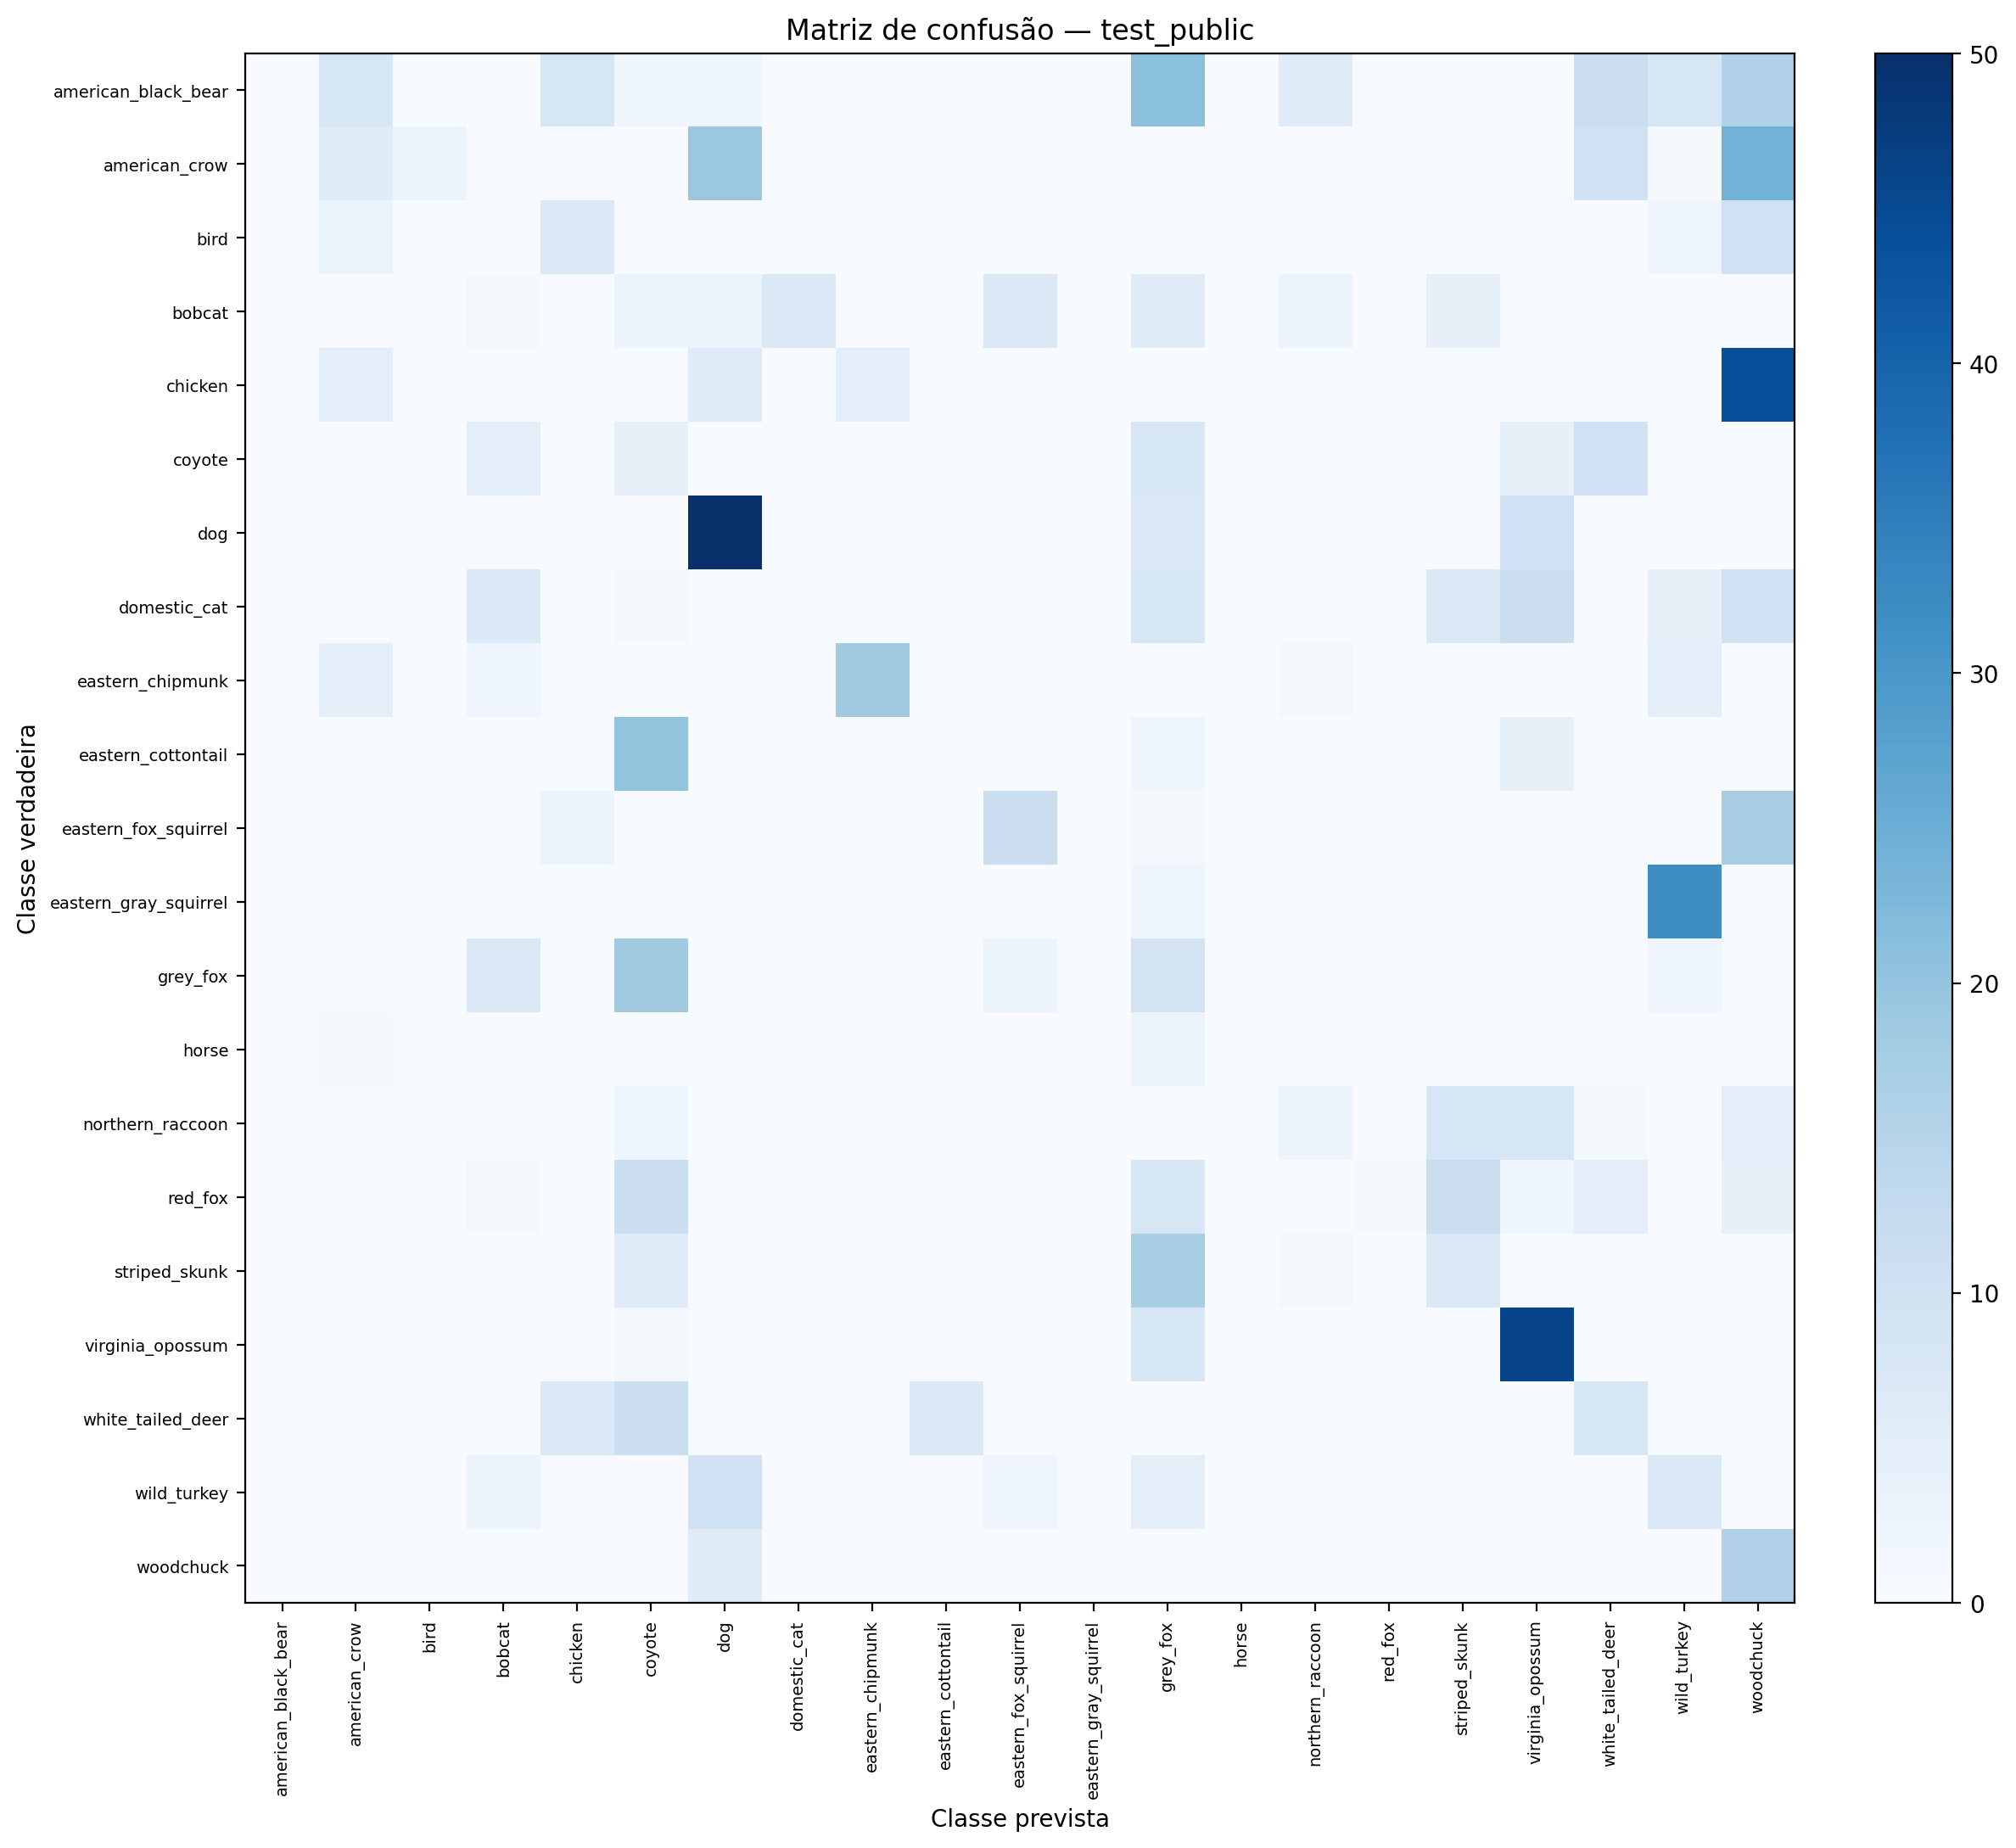

In [ ]:
# Exibir a imagem gerada
from IPython.display import Image
image_path = 'outputs/parte0/cnn_scratch/test_public_confusion_matrix.png'
Image(filename=image_path)

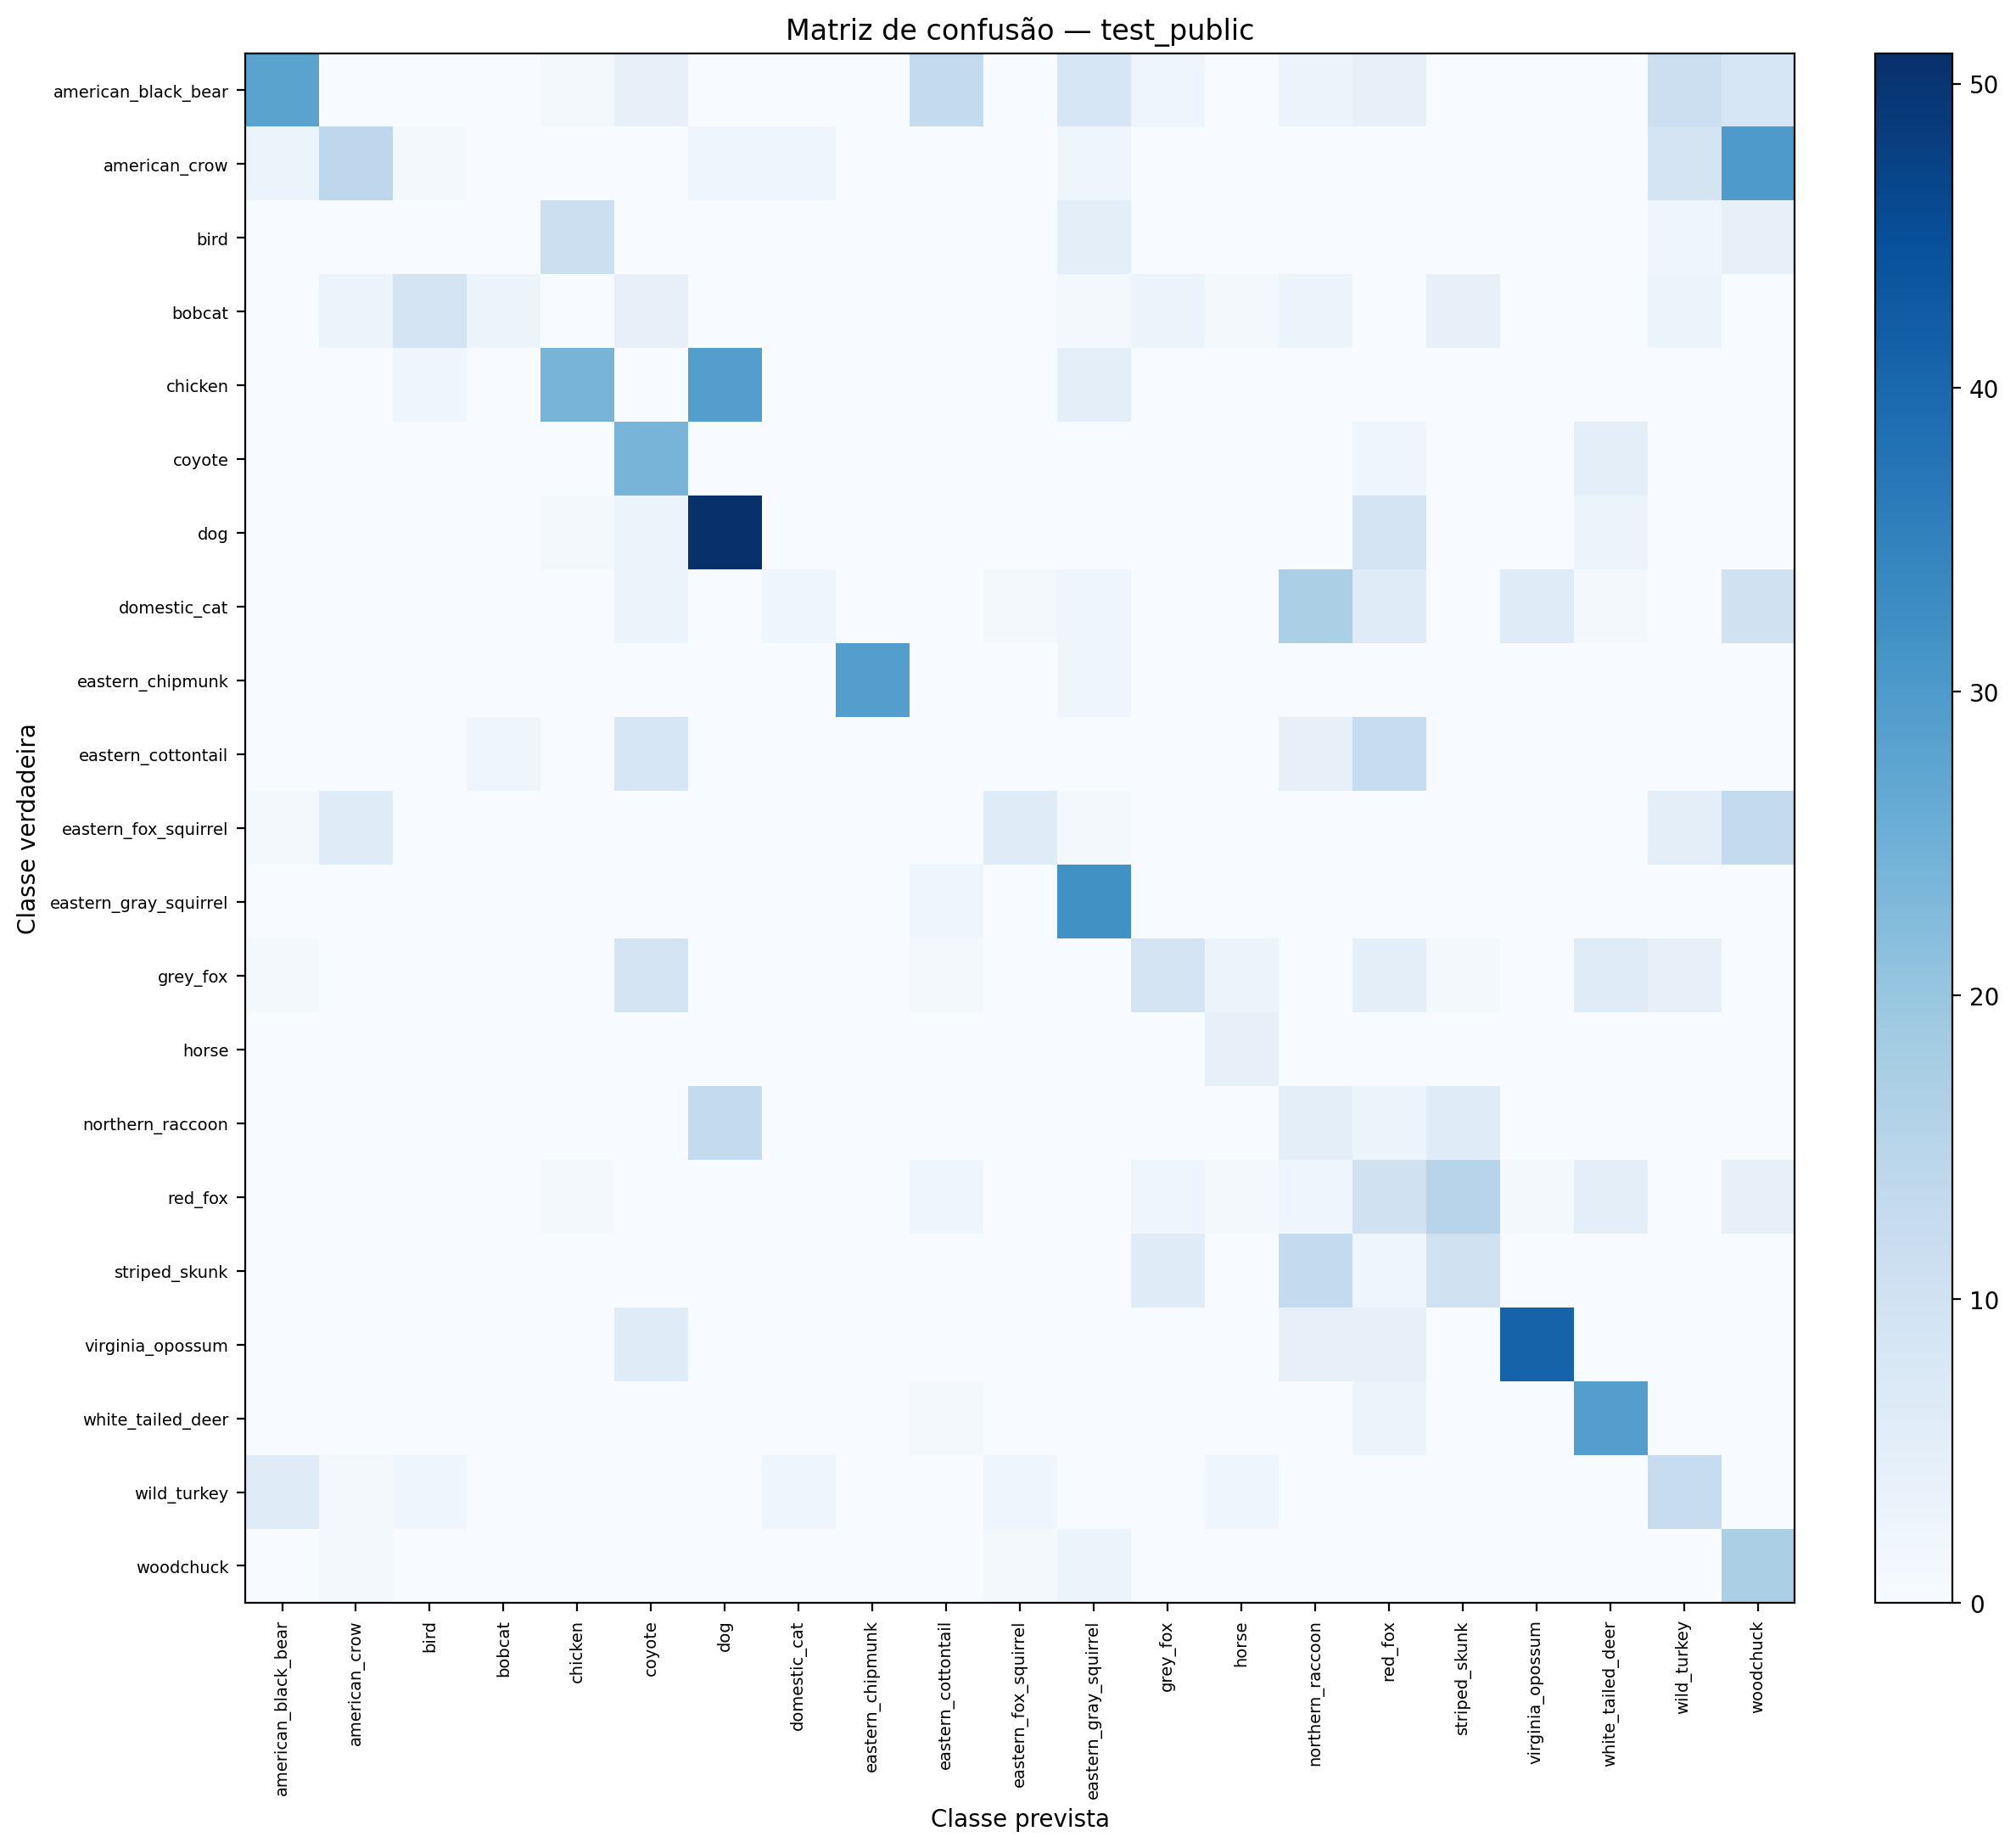

In [ ]:
from IPython.display import Image
image_path = 'outputs/parte0/resnet18/test_public_confusion_matrix.png'
Image(filename=image_path)

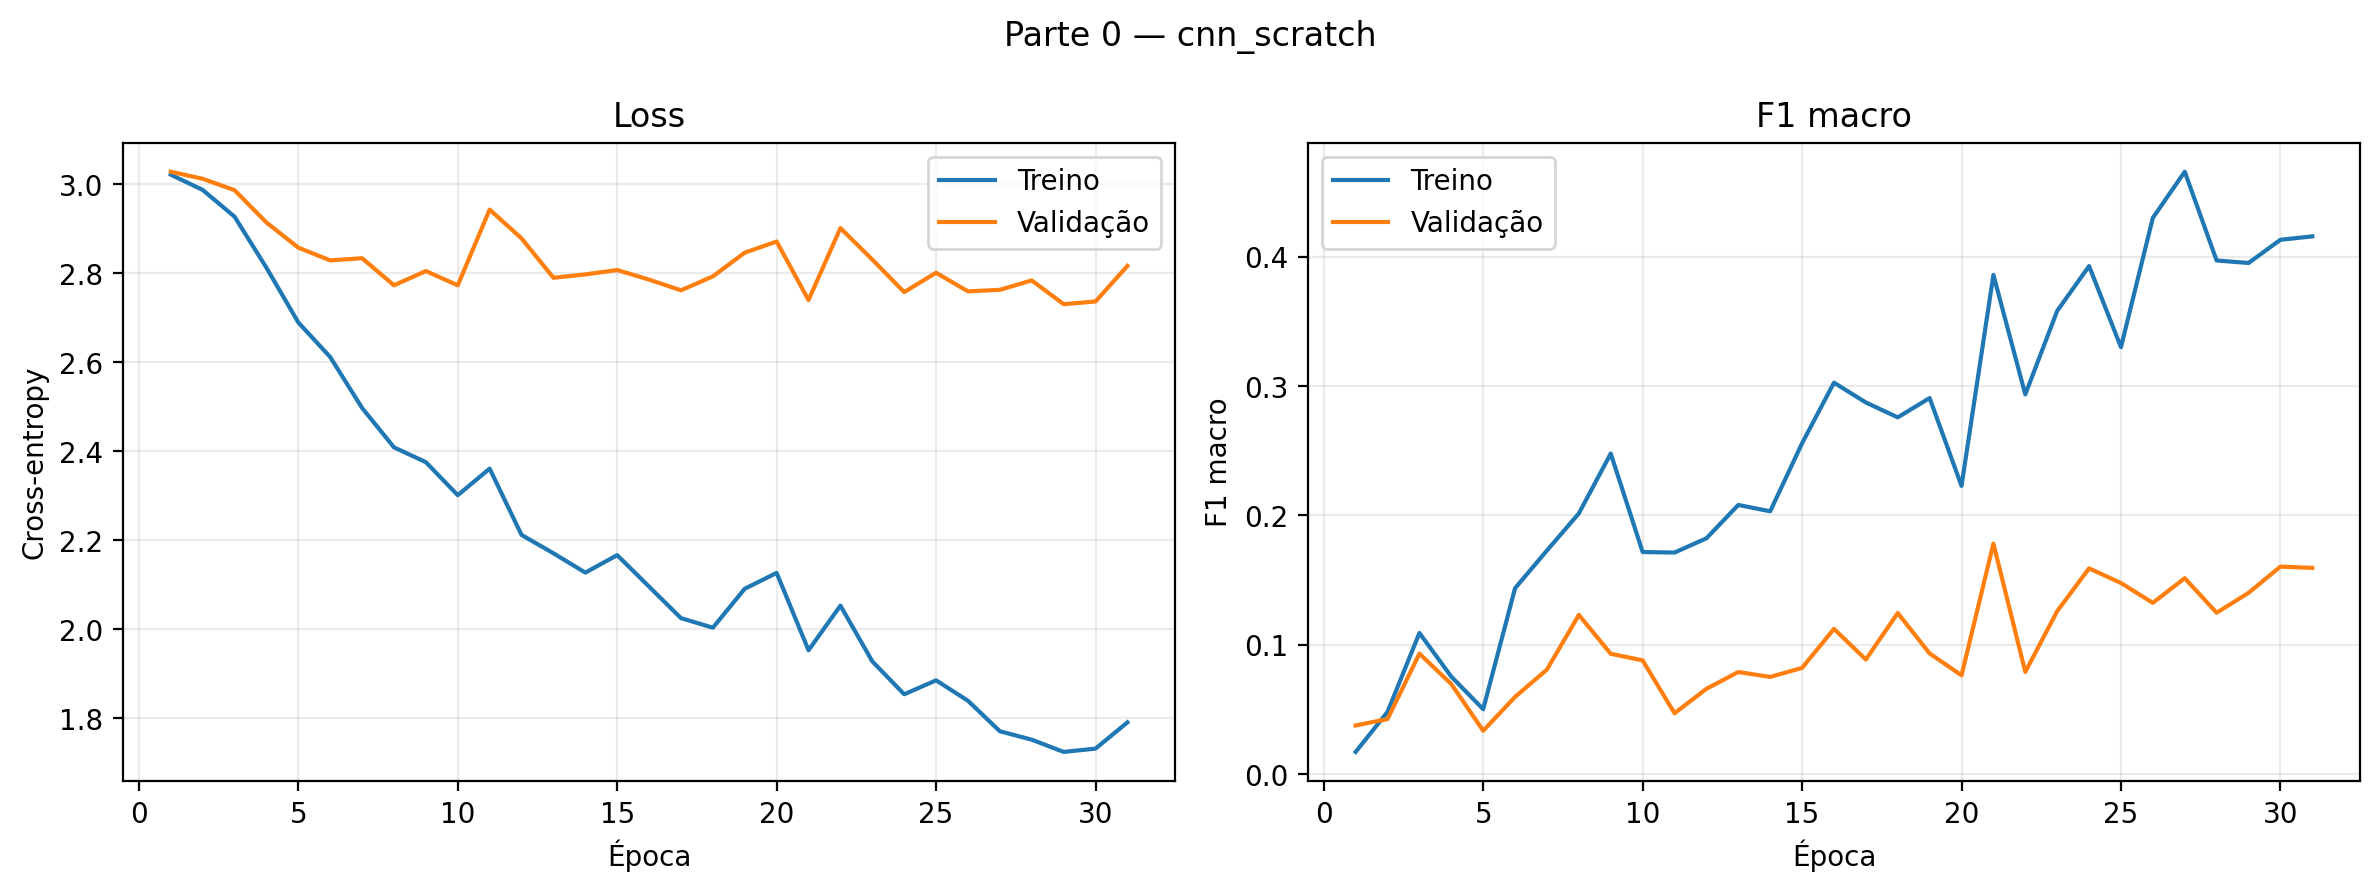

In [ ]:
from IPython.display import Image
image_path = 'outputs/parte0/cnn_scratch/training_curves.png'
Image(filename=image_path)

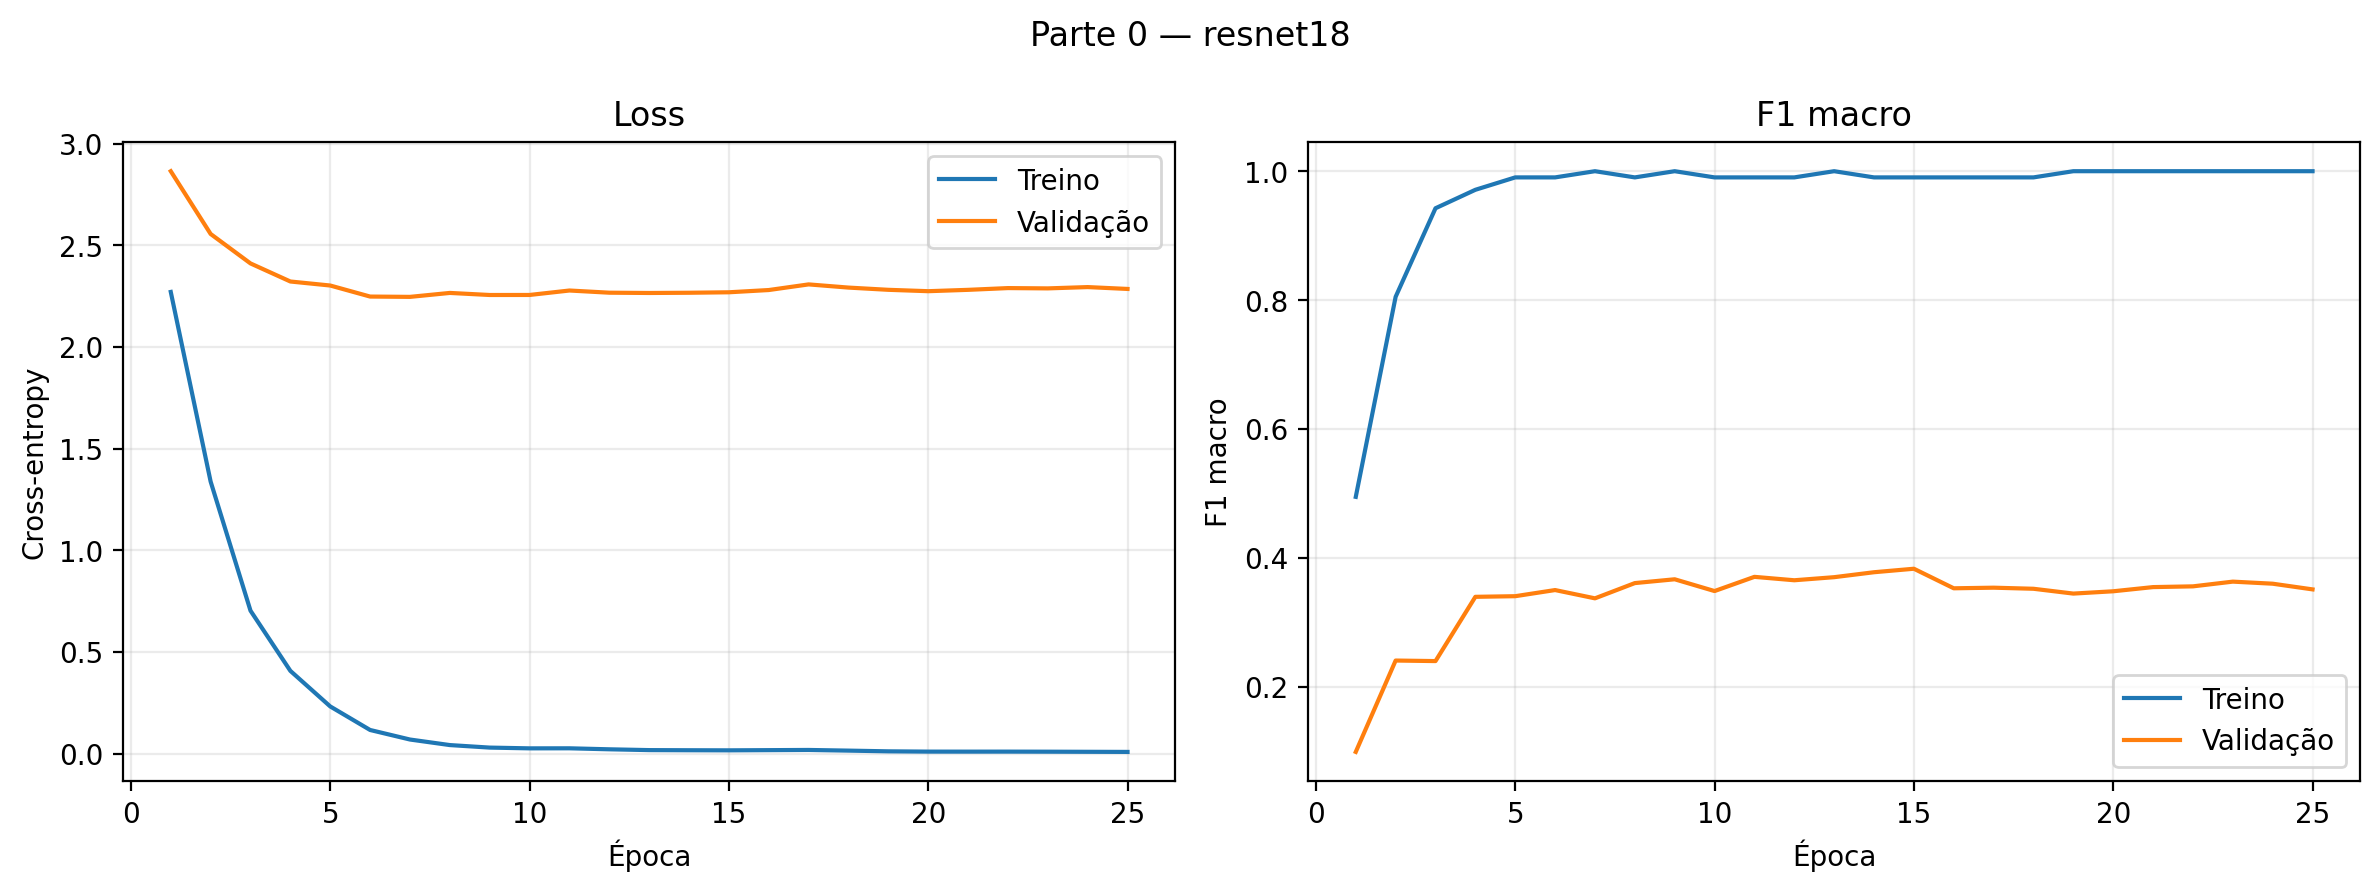

In [ ]:
from IPython.display import Image
image_path = 'outputs/parte0/resnet18/training_curves.png'
Image(filename=image_path)

Parte 1

In [ ]:
!python -m src.train_fixmatch --data-dir data/pa3_dados --output-dir outputs/parte1/fixmatch_standard --method standard --threshold 0.95 --seed 42

[standard] epoch 01 | sup=0.4282 | unsup=0.0107 | aceitação=0.153 | val F1=0.3939 | val acc=0.3861
[standard] epoch 02 | sup=0.0115 | unsup=0.0100 | aceitação=0.367 | val F1=0.4534 | val acc=0.4653
[standard] epoch 03 | sup=0.0110 | unsup=0.0136 | aceitação=0.469 | val F1=0.4320 | val acc=0.4307
[standard] epoch 04 | sup=0.0065 | unsup=0.0108 | aceitação=0.581 | val F1=0.3826 | val acc=0.3614
[standard] epoch 05 | sup=0.0264 | unsup=0.0152 | aceitação=0.646 | val F1=0.3798 | val acc=0.3812
[standard] epoch 06 | sup=0.0072 | unsup=0.0189 | aceitação=0.755 | val F1=0.4101 | val acc=0.4059
[standard] epoch 07 | sup=0.0155 | unsup=0.0297 | aceitação=0.731 | val F1=0.4257 | val acc=0.4158
[standard] epoch 08 | sup=0.0311 | unsup=0.0333 | aceitação=0.752 | val F1=0.4111 | val acc=0.4257
[standard] epoch 09 | sup=0.0128 | unsup=0.0254 | aceitação=0.796 | val F1=0.3826 | val acc=0.3960
[standard] epoch 10 | sup=0.0046 | unsup=0.0209 | aceitação=0.866 | val F1=0.3945 | val acc=0.3911
[standard]

In [ ]:
!python -m src.train_fixmatch --data-dir data/pa3_dados --output-dir outputs/parte1/fixmatch_aligned --method aligned --threshold 0.95 --seed 42

[aligned] epoch 01 | sup=0.4281 | unsup=0.0103 | aceitação=0.151 | val F1=0.3977 | val acc=0.3861
[aligned] epoch 02 | sup=0.0115 | unsup=0.0103 | aceitação=0.360 | val F1=0.4567 | val acc=0.4604
[aligned] epoch 03 | sup=0.0121 | unsup=0.0101 | aceitação=0.448 | val F1=0.4225 | val acc=0.4257
[aligned] epoch 04 | sup=0.0049 | unsup=0.0096 | aceitação=0.560 | val F1=0.4071 | val acc=0.4158
[aligned] epoch 05 | sup=0.0134 | unsup=0.0144 | aceitação=0.614 | val F1=0.3978 | val acc=0.3911
[aligned] epoch 06 | sup=0.0076 | unsup=0.0182 | aceitação=0.702 | val F1=0.3774 | val acc=0.3812
[aligned] epoch 07 | sup=0.0259 | unsup=0.0318 | aceitação=0.739 | val F1=0.3259 | val acc=0.3366
[aligned] epoch 08 | sup=0.0871 | unsup=0.0385 | aceitação=0.635 | val F1=0.4274 | val acc=0.4406
[aligned] epoch 09 | sup=0.0089 | unsup=0.0191 | aceitação=0.737 | val F1=0.4086 | val acc=0.4208
[aligned] epoch 10 | sup=0.0039 | unsup=0.0180 | aceitação=0.807 | val F1=0.3952 | val acc=0.4059
[aligned] epoch 11 |

In [ ]:
!python -m src.diagnose_pseudo_labels --data-dir data/pa3_dados --checkpoint outputs/parte1/fixmatch_standard/best_model.pth --output-dir outputs/parte1/diagnostics_standard

Diagnóstico concluído. ATENÇÃO: test_public foi usado apenas para diagnóstico, não para seleção.
outputs/parte1/diagnostics_standard/pseudo_label_precision_coverage_by_class.csv


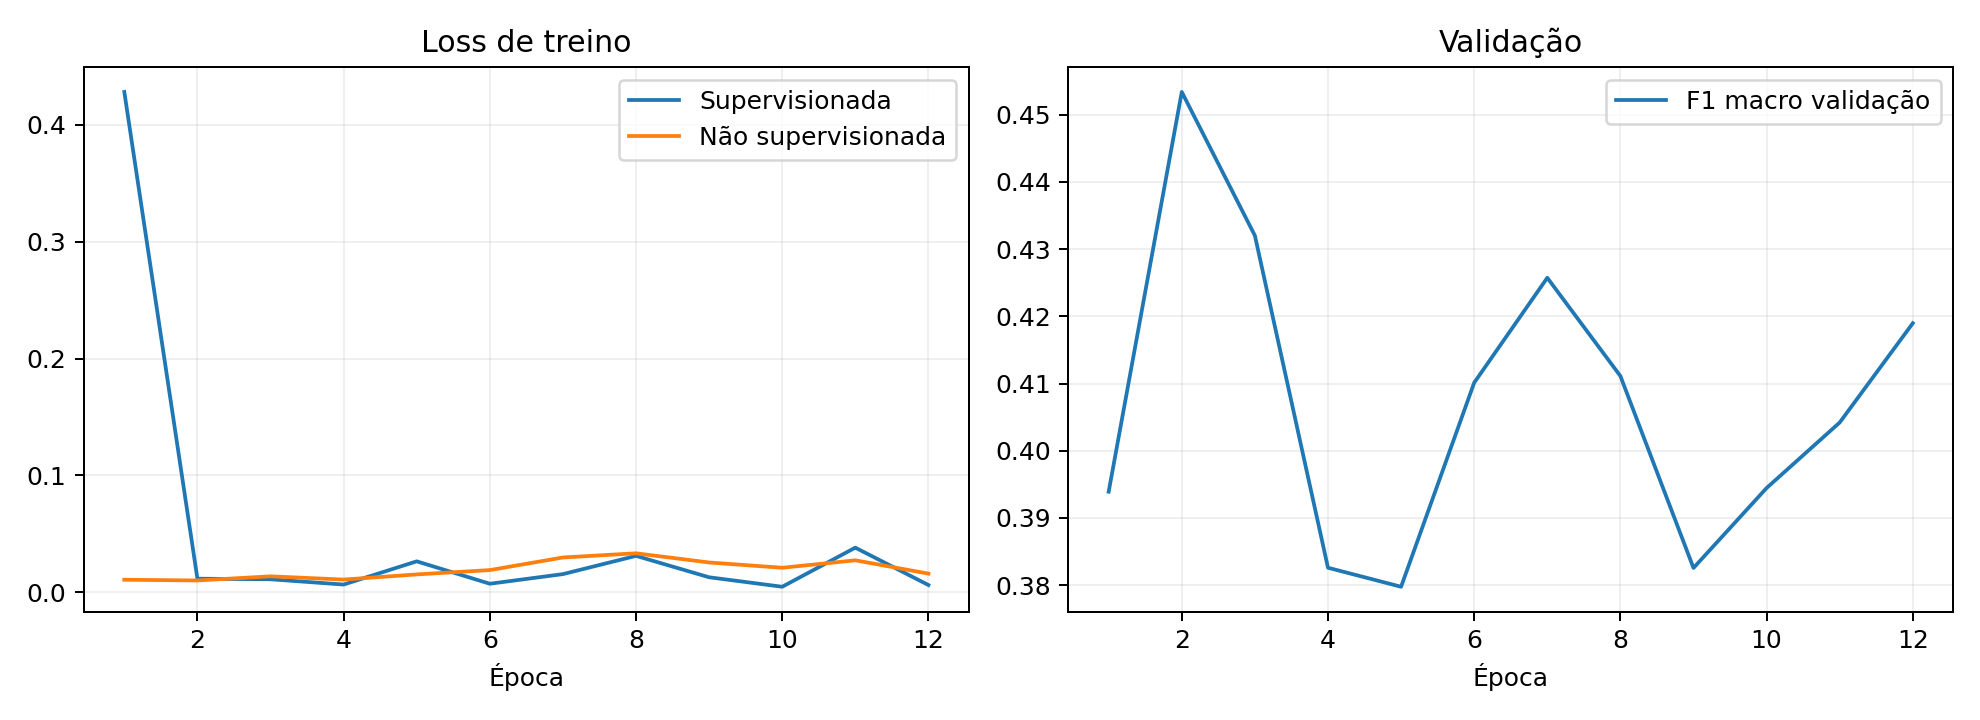

In [ ]:
from IPython.display import Image
image_path = 'outputs/parte1/fixmatch_standard/training_curves.png'
Image(filename=image_path)

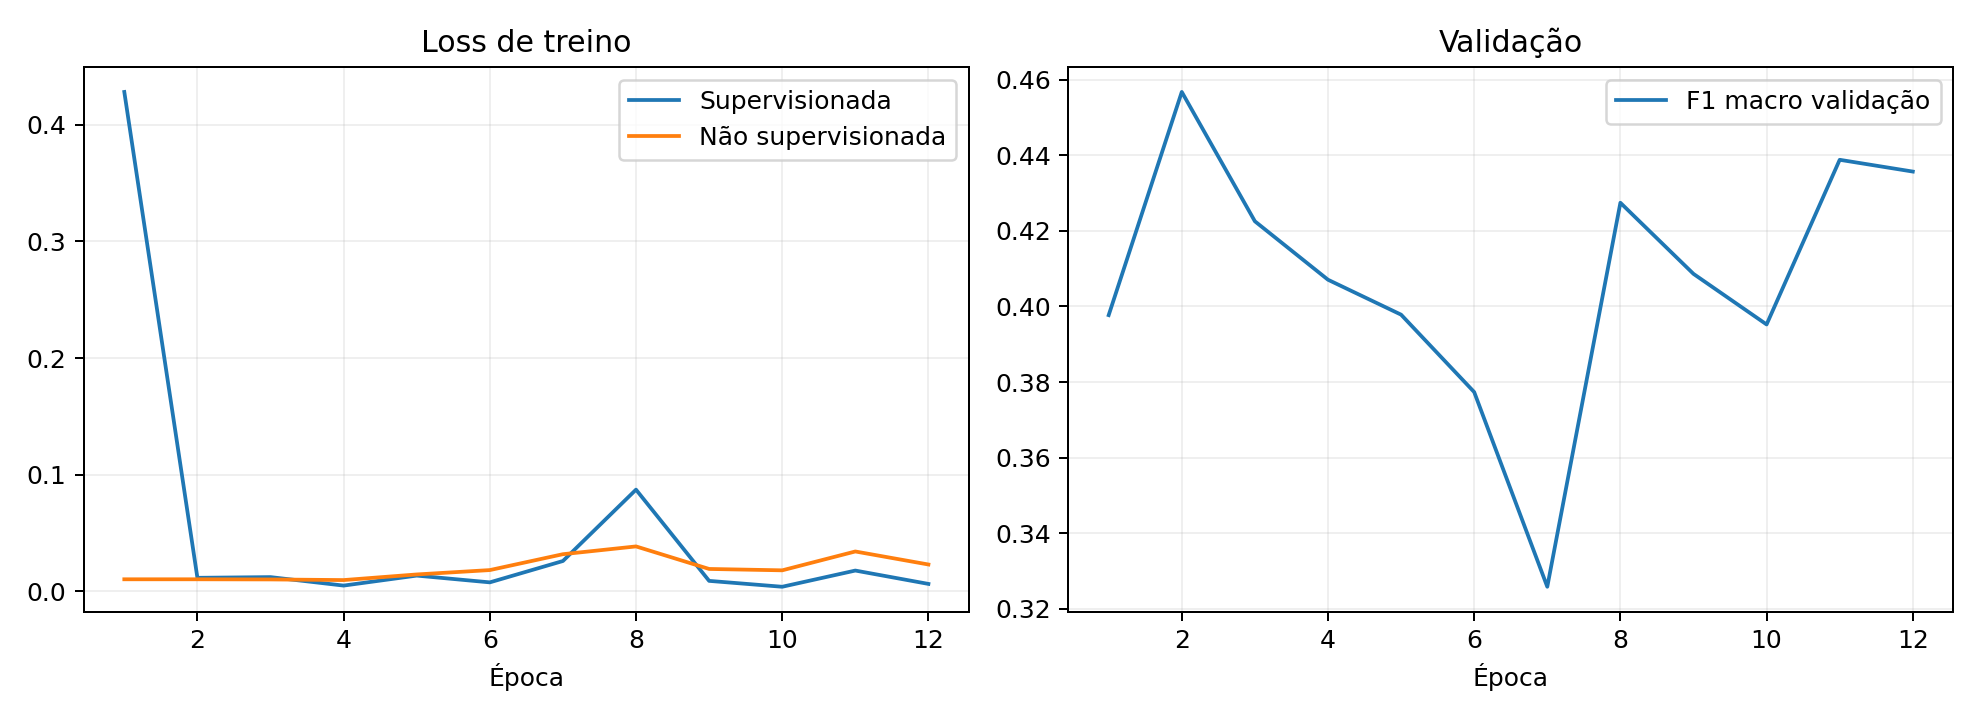

In [ ]:
from IPython.display import Image
image_path = 'outputs/parte1/fixmatch_aligned/training_curves.png'
Image(filename=image_path)

In [ ]:
!python src/plotar_diagnostico.py

Gráficos salvos em: outputs/parte1/diagnostics_standard


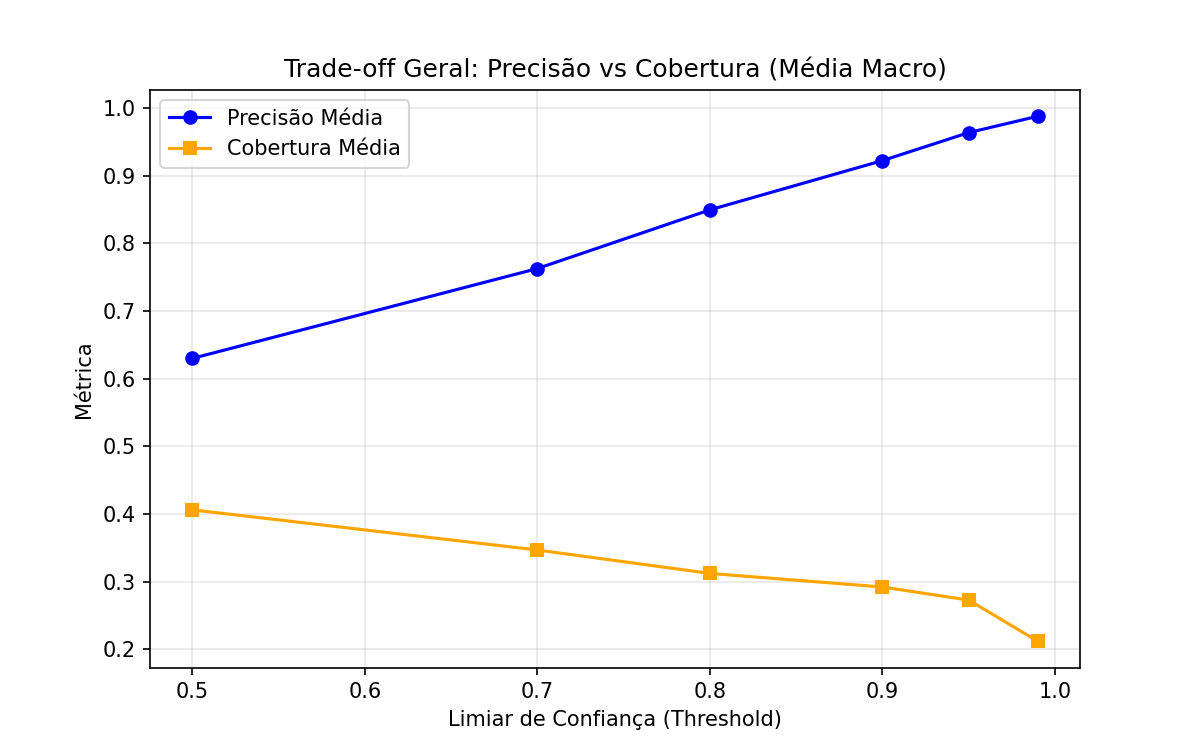

In [ ]:
from IPython.display import Image
image_path = 'outputs/parte1/diagnostics_standard/diagnostico_geral.png'
Image(filename=image_path)

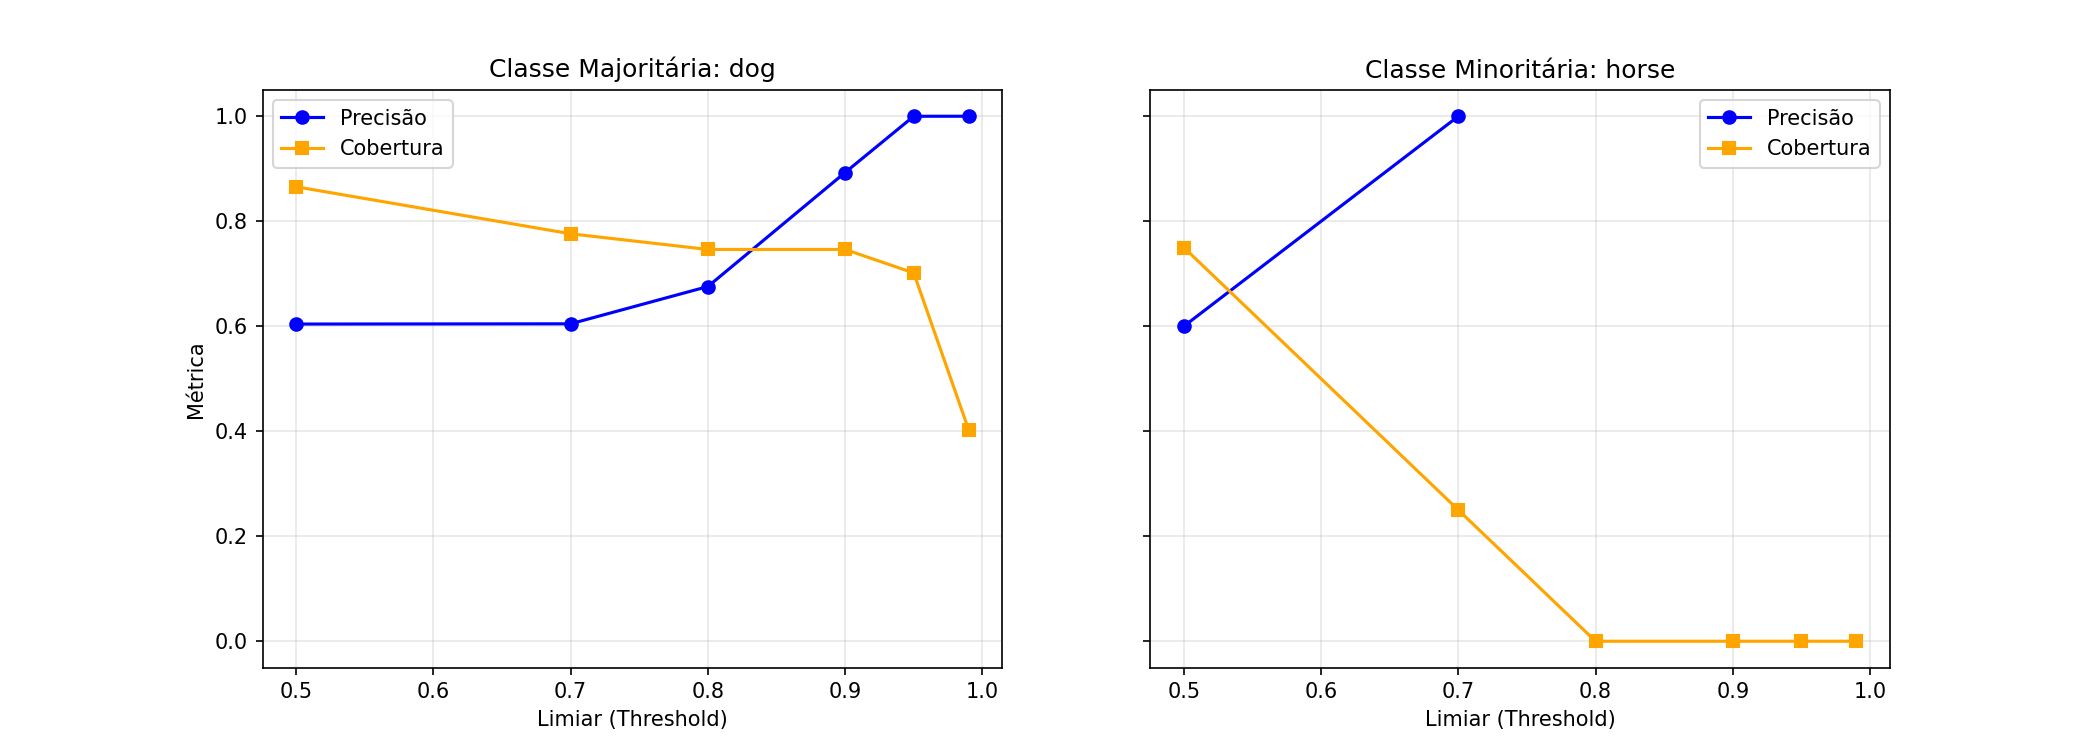

In [ ]:
from IPython.display import Image
image_path = 'outputs/parte1/diagnostics_standard/diagnostico_comparativo.png'
Image(filename=image_path)

In [16]:
!python -m src.parte2 --data-dir data/pa3_dados --output-dir outputs/parte2

/content/DL_PA3/src/parte2.py:164: RuntimeWarning: Usando rotulos_{1,5,20}.csv existentes. Nos três runs do orçamento 5, o subconjunto de imagens será o mesmo; a seed varia a inicialização, embaralhamento e augmentações. Para variar também a amostra, informe --source-labels-csv com pelo menos 20 rótulos por classe.
  warnings.warn(
Dispositivo: cuda
Classes: 21 | Experimentos: 10
Seleção de checkpoint: exclusivamente F1 Macro de val.csv.
test_public: avaliação final após o treinamento, sem seleção de modelos.
[supervised] budget=1 seed=42 epoch=001 val_F1=0.0139 val_acc=0.0446 aceitação=0.000
[supervised] budget=1 seed=42 epoch=002 val_F1=0.0267 val_acc=0.0743 aceitação=0.000
[supervised] budget=1 seed=42 epoch=003 val_F1=0.0340 val_acc=0.0743 aceitação=0.000
[supervised] budget=1 seed=42 epoch=004 val_F1=0.0775 val_acc=0.1238 aceitação=0.000
[supervised] budget=1 seed=42 epoch=005 val_F1=0.1458 val_acc=0.1931 aceitação=0.000
[supervised] budget=1 seed=42 epoch=006 val_F1=0.1284 val_ac